In [5]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold,cross_val_predict

from src.data import load_data, clean_data, split_data
from src.features import build_preprocessor
from src.evaluation import net_savings,savings_curve, GAIN_TP,COST_FP

df = clean_data(load_data())
X_train, X_test, y_train, y_test = split_data(df)

model = Pipeline([
    ("prep", build_preprocessor()),
    ("model", LogisticRegression(max_iter=1000)),
])
print(GAIN_TP, COST_FP)     # 184.0 50

184.0 50


In [6]:


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
print(oof_proba[:5].round(3))

[0.378 0.294 0.04  0.09  0.37 ]


threshold           0.25
net_savings    166148.00
Name: 20, dtype: float64


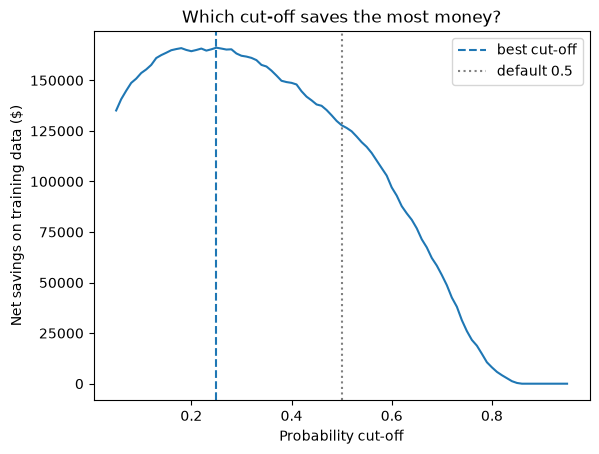

In [7]:
curve = savings_curve(y_train, oof_proba)
best = curve.loc[curve["net_savings"].idxmax()]
print(best)

plt.plot(curve["threshold"], curve["net_savings"])
plt.axvline(best["threshold"], linestyle="--", label="best cut-off")
plt.axvline(0.5, color="grey", linestyle=":", label="default 0.5")
plt.xlabel("Probability cut-off")
plt.ylabel("Net savings on training data ($)")
plt.title("Which cut-off saves the most money?")
plt.legend()
plt.show()

In [9]:
best_threshold = float(best["threshold"])

model.fit(X_train, y_train)                        # learn from all training data
test_proba = model.predict_proba(X_test)[:, 1]     # probabilities for unseen customers

strategies = {
    "Contact nobody": np.zeros(len(y_test), dtype=int),
    "Contact everybody": np.ones(len(y_test), dtype=int),
    "Model, default cut-off 0.5": (test_proba >= 0.5).astype(int),
    f"Model, cost-based cut-off {best_threshold:.2f}": (test_proba >= best_threshold).astype(int),
}

rows = []
for name, pred in strategies.items():
    rows.append({
        "strategy": name,
        "contacted": int(pred.sum()),
        "churners reached": int(((pred == 1) & (y_test == 1)).sum()),
        "wasted offers": int(((pred == 1) & (y_test == 0)).sum()),
        "net savings ($)": net_savings(y_test, pred),
    })
print(pd.DataFrame(rows))

                         strategy  contacted  churners reached  wasted offers  \
0                  Contact nobody          0                 0              0   
1               Contact everybody       1409               374           1035   
2      Model, default cut-off 0.5        318               209            109   
3  Model, cost-based cut-off 0.25        609               303            306   

   net savings ($)  
0              0.0  
1          17066.0  
2          33006.0  
3          40452.0  
